# Exploratory p21/Rb/pRb cell-cycle progression score

This notebook creates a per-cell, biologically motivated **G1-to-S progression proxy** from p21, Rb, and pRb mean-intensity measurements. It does not claim to identify G1, S, G2, or M as validated phases. p21 and phosphorylated Rb are context dependent, total Rb does not provide a monotonic cycle clock, and pRb/Rb fluorescence is not a calibrated phosphorylation fraction unless channels are calibrated. The supplied sample is NTC-only, so scores describe relative marker states in this sample, not perturbation-induced phase shifts.

The score combines lower p21 with higher relative pRb-vs-Rb signal, robustly scales within well, then reports a within-well percentile from 0 to 1. Discordant evidence is flagged as ambiguous. PCA below is computed from the three marker values **only for visualization** and is not used in score calculation. DNA content or trusted phase labels should be used later for independent validation.

Run from the repository root. Script outputs are written under `reports/ops0077_cell_cycle_score/`.

## Biological rationale and limitations

- p21/CDKN1A inhibits cyclin-CDK activity; elevated p21 commonly accompanies arrest/quiescence or stress, while lower p21 can be consistent with active G1/S progression. It is not a phase-specific marker.
- Rb phosphorylation generally reduces Rb-mediated E2F repression and increases around G1/S. Hyperphosphorylated Rb can also persist beyond S entry, so this does not resolve S, G2, or M.
- Total Rb abundance is not assumed to increase or decrease monotonically across the cycle. The pRb-to-Rb intensity relation is used only as a relative proxy. Raw fluorescence ratios are affected by antibody affinity, staining, exposure, and channel scaling.
- The implemented score is a transparent heuristic, not a learned model: 65% difference between the within-well robust z-scores of log(pRb) and log(Rb), plus 35% robust-scaled inverse log(p21), followed by a within-well percentile. No fitted PCA coordinates enter the score.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'scripts/score_ops0077_cell_cycle_markers.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate project root.')
INPUT = ROOT / 'data/altair/ops0077_4i/OPS0077_NTC_OrganelleProfiler_pRb_Rb_p21.h5ad'
OUT = ROOT / 'reports/ops0077_cell_cycle_score'
COMMAND = [sys.executable, str(ROOT / 'scripts/score_ops0077_cell_cycle_markers.py'), '--input', str(INPUT), '--outdir', str(OUT)]
run = subprocess.run(COMMAND, check=True, capture_output=True, text=True)
summary = json.loads((OUT / 'score_summary.json').read_text())
scores = pd.read_csv(OUT / 'per_cell_marker_stage_scores.csv')
print(run.stdout)
print('Scored cells:', summary['scored_cells'], '/', summary['cells'])

{
  "input": "<project-root>/data/altair/ops0077_4i/OPS0077_NTC_OrganelleProfiler_pRb_Rb_p21.h5ad",
  "cells": 52220,
  "scored_cells": 17161,
  "unscored_cells": 35059,
  "group_column": "well_canonical",
  "group_counts": {
    "A/2/0": 18757,
    "A/3/0": 17448,
    "A/1/0": 16015
  },
  "feature_names": {
    "pRb": "op_4i_r3_prb_intensity_mean_mean",
    "Rb": "op_4i_r3_rb_intensity_mean_mean",
    "p21": "op_4i_r4_p21_intensity_mean_mean"
  },
  "formula": "within-group percentile of 0.65*(robust_z(log1p(pRb))-robust_z(log1p(Rb))) + 0.35*robust_z(-log1p(p21)); each robust z uses median/IQR and is clipped to +/-5",
  "stage_proxy_thresholds": {
    "below_1_3": "G1_like_low_progression_proxy",
    "1_3_to_2_3": "intermediate_uncertain",
    "above_2_3": "G1_S_entry_like_high_progression_proxy",
    "discordance_rule": "If both marker evidence terms have magnitude >=0.5 and opposite signs, label ambiguous_discordant_markers."
  },
  "stage_counts": {
    "not_scored_missing_marker"

## Score distribution and marker evidence

Threshold labels are descriptive bins of this relative proxy, not validated biological phases. Discordant p21 and pRb/Rb evidence takes precedence and is flagged as ambiguous.

,cells
stage_proxy,
not_scored_missing_marker,35059
G1_like_low_progression_proxy,5111
intermediate_uncertain,4423
G1_S_entry_like_high_progression_proxy,4372
ambiguous_discordant_markers,3255


,cell_cycle_stage_score,pRb_to_Rb_ratio,p21_intensity
stage_proxy,,,
G1_S_entry_like_high_progression_proxy,0.847061,2.510593,2048.859375
G1_like_low_progression_proxy,0.161845,1.044225,2991.479248
ambiguous_discordant_markers,0.594985,1.269588,1992.151123
intermediate_uncertain,0.496388,1.653333,2713.663086
not_scored_missing_marker,NaN,1.694610,2459.864258


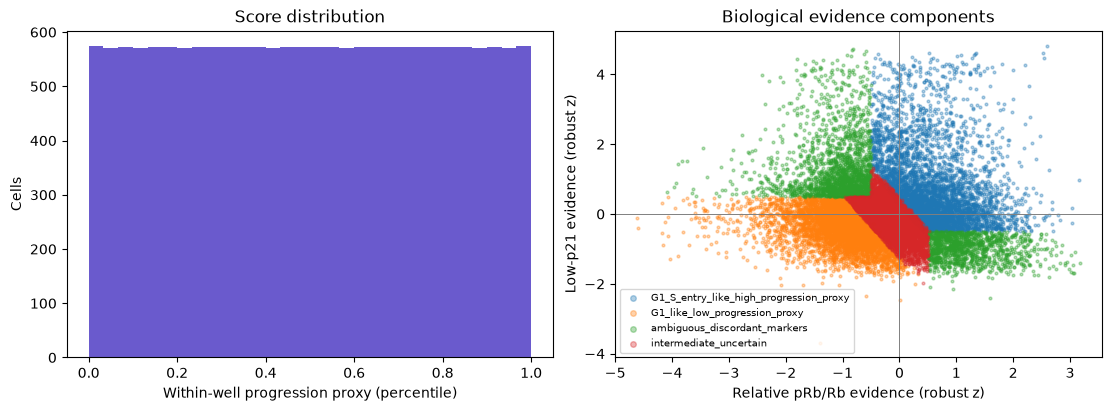

In [2]:
display(scores['stage_proxy'].value_counts(dropna=False).rename_axis('stage_proxy').to_frame('cells'))
display(scores.groupby('stage_proxy', dropna=False)[['cell_cycle_stage_score', 'pRb_to_Rb_ratio', 'p21_intensity']].median())
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
scored = scores['cell_cycle_stage_score'].notna()
axes[0].hist(scores.loc[scored, 'cell_cycle_stage_score'], bins=30, color='slateblue')
axes[0].set(xlabel='Within-well progression proxy (percentile)', ylabel='Cells', title='Score distribution')
for stage, frame in scores.loc[scored].groupby('stage_proxy'):
    axes[1].scatter(frame['pRb_Rb_evidence_z'], frame['low_p21_evidence_z'], s=4, alpha=0.35, label=stage)
axes[1].axhline(0, color='grey', linewidth=0.7)
axes[1].axvline(0, color='grey', linewidth=0.7)
axes[1].set(xlabel='Relative pRb/Rb evidence (robust z)', ylabel='Low-p21 evidence (robust z)', title='Biological evidence components')
axes[1].legend(fontsize=7, markerscale=2)
plt.show()

## PCA visualization only

This PCA is calculated from log1p-transformed, standardized pRb, Rb, and p21 mean intensities on complete cells. It helps visualize whether the heuristic score varies smoothly over marker space. The score was calculated independently and no PCA axis or loading contributes to it. PCA cannot identify a cycle direction without external labels.

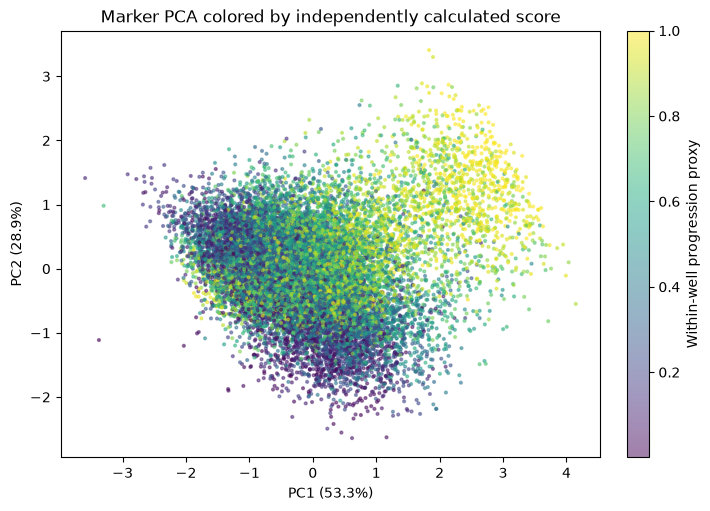

In [3]:
adata = ad.read_h5ad(INPUT, backed='r')
var = adata.var
feature_indices = []
for organelle in ['4i_r3_prb', '4i_r3_rb', '4i_r4_p21']:
    select = var['source'].eq('organelle_profiler') & var['organelle'].eq(organelle) & var['category'].eq('intensity') & var['metric'].eq('intensity_mean') & var['aggregation'].eq('mean')
    found = np.flatnonzero(select.to_numpy())
    if len(found) != 1:
        raise ValueError(f'Expected one intensity feature for {organelle}')
    feature_indices.append(int(found[0]))
marker_values = np.asarray(adata.X[:, feature_indices], dtype=np.float64)
adata.file.close()
complete = np.isfinite(marker_values).all(axis=1)
log_values = np.log1p(marker_values[complete])
center = np.median(log_values, axis=0)
scale = np.quantile(log_values, 0.75, axis=0) - np.quantile(log_values, 0.25, axis=0)
scale[scale == 0] = 1
z = (log_values - center) / scale
_, singular, vt = np.linalg.svd(z - z.mean(axis=0), full_matrices=False)
coordinates = (z - z.mean(axis=0)) @ vt[:2].T
variance = singular[:2] ** 2 / np.square(singular).sum()
plot = scores.loc[complete].copy()
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=plot['cell_cycle_stage_score'], s=4, alpha=0.5, cmap='viridis')
fig.colorbar(points, ax=ax, label='Within-well progression proxy')
ax.set(xlabel=f'PC1 ({variance[0]:.1%})', ylabel=f'PC2 ({variance[1]:.1%})', title='Marker PCA colored by independently calculated score')
fig.savefig(OUT / 'marker_score_pca_visualization.png', dpi=180)
plt.show()

## Interpretation and validation plan

A high value means the cell ranks toward the high-pRb-relative-to-Rb / low-p21 end of its well’s measured cells; a low value means the opposite. It does **not** mean a calibrated cell-cycle time or a known S/G2/M phase. The current file contains NTC cells and no DNA-content labels. Once paired DNA-content measurements are available, assess monotonicity and phase separation by held-out well/replicate, tune or reject weights and thresholds on training wells only, and report calibration and uncertainty. Confirm pRb antibody epitope/acquisition linearity and investigate well effects before comparing scores across batches.